# ResNet generalists (RQ1 baseline)

Trains **one ResNet per leave-one-out fold** on all seen generators together: the single-detector baseline
for the ResNet pools, like `meta/generalist.py` is for CLIP. See `resnet/generalist.py`.

- **Folds:** the 7 single folds plus `SD+wukong` (for `merge_siblings=True`), so 8 networks.
- **Train:** the expert recipe (`resnet/train.py`) on the `expert_train` images of every seen expert together,
  `expert_val` of the seen experts for early stopping and the temperature. Held-out generators are never seen.
- **Score:** every image of `meta_val` and `test` with every generalist → feature set `resnet18_generalists`.
- **Evaluate:** same columns as the meta-learners (`meta.loo`): threshold from seen `meta_val`, AUROC etc. on the
  held-out generators of `EVAL_POOL`.

**Time:** each generalist trains on 6x the images of one expert (~60k per epoch), so expect roughly 6x the
expert time per epoch. ResNet-18 is ~2.5x faster than ResNet-50 (~17 min per epoch on an M4 for ResNet-50).

**Safe to stop and rerun:** finished generalists and scored images are saved and skipped.
Set `LIMIT = 100` first for a test run of the whole notebook; it saves to separate folders.


In [1]:
import sys
sys.path.insert(0, "../..")  # repo root, so `common`, `data`, `meta` and `resnet` are importable

import matplotlib.pyplot as plt
import pandas as pd

from data import config
from resnet.generalist import FOLDS, run_generalist, score, train_all

ARCH = "resnet50"  # ~2.5x faster than resnet50, and the expert pools barely differed
LIMIT = None  # e.g. 100 for a test run: 100 images per label, pool and expert, saved separately
EPOCHS = 1 if LIMIT else 8
BATCH_SIZE = 64  # training; lower to 32 if you run out of memory
NUM_WORKERS = 4
TRAIN_FOLDS = None  # None = all of FOLDS, or e.g. ["ADM", "BigGAN"]
MERGE_SIBLINGS = True  # evaluate with SD and wukong held out together
EVAL_POOL = "test"  # "meta_val" while developing, so test stays untouched

print("dataset:", config.dataset_dir(), config.dataset_dir().exists())
print("folds:", FOLDS)


dataset: /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c True
folds: {'ADM': ['ADM'], 'BigGAN': ['BigGAN'], 'glide': ['glide'], 'Midjourney': ['Midjourney'], 'SD': ['SD'], 'VQDM': ['VQDM'], 'wukong': ['wukong'], 'SD+wukong': ['SD', 'wukong']}


## 1 · Train and calibrate one generalist per fold

In [2]:
infos = train_all(TRAIN_FOLDS, epochs=EPOCHS, limit=LIMIT, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, arch=ARCH)

[10:37:06] [ADM] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50_generalists/ADM.pt to retrain)
[10:37:06] [BigGAN] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50_generalists/BigGAN.pt to retrain)
[10:37:06] [glide] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50_generalists/glide.pt to retrain)
[10:37:06] [Midjourney] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50_generalists/Midjourney.pt to retrain)
[10:37:06] [SD] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50_generalists/SD.pt to retrain)
[10:37:06] [VQDM] already trained, skipping (delete /Users/tim/Developer/SC4001-Metalearners-

### Training curves

Validation loss is on the `expert_val` images of the fold's seen experts. `T` is the calibration temperature.

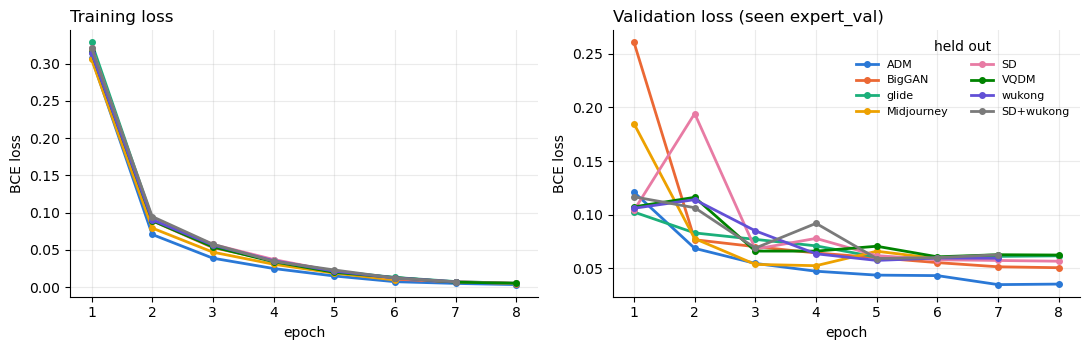

,held out,n train,best epoch,epochs run,val auc,val acc,val loss,calibrated loss,T,minutes
0,ADM,60000,7,8,0.9993,0.9896,0.0349,0.0305,1.4952,133.0500
1,BigGAN,60000,8,8,0.9986,0.9852,0.0506,0.0439,1.5254,134.8833
2,glide,60000,6,8,0.9979,0.9828,0.0597,0.0522,1.5388,135.5667
3,Midjourney,60000,4,6,0.9984,0.9819,0.0525,0.0508,1.2232,100.5500
4,SD,60000,8,8,0.9983,0.9841,0.0567,0.0477,1.6140,130.2833
5,VQDM,60000,6,8,0.9980,0.9813,0.0608,0.0516,1.6070,129.8000
6,wukong,60000,5,7,0.9981,0.9812,0.0574,0.0527,1.3984,113.6500
7,SD+wukong,50000,5,7,0.9978,0.9817,0.0592,0.0540,1.4180,94.7833


In [3]:
# Categorical slots in fixed order, one per fold.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#7a7a7a"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for color, (fold, info) in zip(COLORS, infos.items()):
    history = pd.DataFrame(info["history"])
    axes[0].plot(history.epoch, history.train_loss, color=color, lw=2, marker="o", ms=4, label=fold)
    axes[1].plot(history.epoch, history.val_loss, color=color, lw=2, marker="o", ms=4, label=fold)
for ax, title in zip(axes, ["Training loss", "Validation loss (seen expert_val)"]):
    ax.set_title(title, loc="left")
    ax.set_xlabel("epoch")
    ax.set_ylabel("BCE loss")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, fontsize=8, ncol=2, title="held out")
plt.tight_layout()
plt.show()

pd.DataFrame([{
    "held out": fold, "n train": info["n_train"], "best epoch": info["best_epoch"], "epochs run": info["epochs_run"],
    "val auc": info["val"]["auc"], "val acc": info["val"]["acc"], "val loss": info["val"]["loss"],
    "calibrated loss": info["val_calibrated_loss"], "T": info["temperature"],
    "minutes": info["train_seconds"] / 60,
} for fold, info in infos.items()]).round(4)


## 2 · Score `meta_val` and `test` with every generalist

Needs all 8 generalists trained.

In [4]:
score(limit=LIMIT, num_workers=NUM_WORKERS, arch=ARCH)

[10:37:19] resnet50_generalists: 48000 images in pools ['meta_val', 'test'], 10000 done, 38000 to do
[10:40:34] saved 5000 images to part_0002.npz
[10:41:21] 6400/38000 images (16.8%), elapsed 0h04m01s, ETA 0h19m53s
[10:43:48] saved 5000 images to part_0003.npz
[10:45:31] 12800/38000 images (33.7%), elapsed 0h08m11s, ETA 0h16m07s
[10:47:00] saved 5000 images to part_0004.npz
[10:50:13] 19200/38000 images (50.5%), elapsed 0h12m53s, ETA 0h12m37s
[10:50:48] saved 5000 images to part_0005.npz
[10:54:01] saved 5000 images to part_0006.npz
[10:54:21] 25600/38000 images (67.4%), elapsed 0h17m01s, ETA 0h08m14s
[10:57:18] saved 5000 images to part_0007.npz
[10:58:35] 32000/38000 images (84.2%), elapsed 0h21m15s, ETA 0h03m59s
[11:00:33] saved 5000 images to part_0008.npz
[11:02:51] saved 3000 images to part_0009.npz
[11:02:51] resnet50_generalists: 38000 images in 0h25m31s


## 3 · Leave-one-out results

One row per fold: `auc`, `ap`, `acc` on the held-out generators of `EVAL_POOL`, `seen_auc` on the others,
`gap` = `seen_auc` − `auc`. Same columns as the meta-learners and the CLIP generalist.

In [5]:
run_generalist(MERGE_SIBLINGS, EVAL_POOL, limit=LIMIT, arch=ARCH).round(4)

,generators,n_train,n_val,n_eval,auc,ap,acc,seen_auc,gap
held out,,,,,,,,,
ADM,ADM,60000.0,14000.0,4000.0,0.9654,0.9669,0.7585,0.9996,0.0342
BigGAN,BigGAN,60000.0,14000.0,4000.0,0.9711,0.9672,0.7558,0.9991,0.0281
glide,glide,60000.0,14000.0,4000.0,0.9991,0.9991,0.9875,0.9991,-0.0000
Midjourney,Midjourney,60000.0,14000.0,4000.0,0.9656,0.9677,0.8065,0.9989,0.0333
VQDM,VQDM,60000.0,14000.0,4000.0,0.9886,0.9880,0.8725,0.9989,0.0103
SD+wukong,"stable_diffusion_v_1_4, stable_diffusion_v_1_5...",50000.0,10000.0,12000.0,0.9808,0.9782,0.8689,0.9988,0.0180
mean,NaN,NaN,NaN,NaN,0.9784,0.9779,0.8416,0.9991,0.0207
